# code_184 · Search strategies consume validation and computation differently

**Book:** section 35.2. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_35_GUIDE.md), [execution evidence](../CHAPTER_35_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_184).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or field causal conclusions. Configuration spaces, data roles, selection information and resource accounting are explicit. Generated records do not establish field performance or intervention validity. Original scoped mechanisms are identified separately from native library models.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=7684;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 7684


<a id="static-search-and-fidelity"></a>
 ## Fit real candidates at declared resource levels
 Sixty independent buildings supply four records each;36 source/12 development/12 final buildings stay disjoint. Standardization fits source only. Every static candidate uses the same 6→12→1 Tanh architecture and initial weights. The 64-point proposal pool is uniform in log learning rate 10^-4–10^-1 and log weight decay 10^-6–10^-1. One resource unit is one full-source Adam update, not a wall-clock second. A ceiling of 432 updates permits 16 random full-fidelity trials at 27 updates, or 16 actual GP expected-improvement trials (first four shared with random search). The GP uses a fixed Matérn 5/2 kernel, length 0.35 on normalized log parameters, alpha 10^-5 and no fitted kernel search. EI is computed from posterior mean and standard deviation over untried pool entries; this is an original small GP optimizer, not a full paper benchmark.

 Four aggressive successive-halving brackets each train 27 candidates for 1 update,9 for 3,3 for 9 and 1 for 27. Every rung restarts from the original weights: cost 108 per bracket,432 total, without falsely counting continued training. Hyperband's R 27/eta 3 bracket rule gives initial counts 27/12/6/4 and costs 108/99/108/108=423; nine units remain unused. Its allocation follows the primary bracket construction, but this declared comparison selects only candidates actually assessed at 27 updates, rather than the original algorithm's smallest intermediate loss rule. Development scores determine proposals, promotion and winners. Final outcomes are untouched until the search rules have finished.


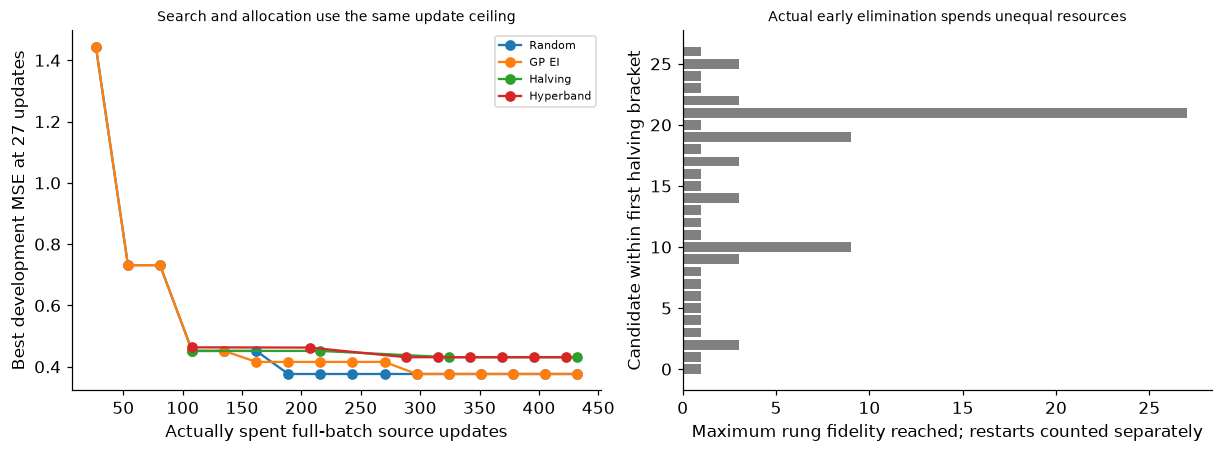

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
from scipy.stats import norm
group=np.repeat(np.arange(60),4);X=rng.normal(size=(240,6));X[:,:2]+=rng.normal(size=(60,2))[group];Y=1.2*np.sin(X[:,0])+.6*X[:,1]*X[:,2]-.5*X[:,3]+rng.normal(scale=.35,size=240)+rng.normal(scale=.3,size=60)[group];source=group<36;development=(group>=36)&(group<48);final=group>=48;scaler=StandardScaler().fit(X[source]);sx=torch.tensor(scaler.transform(X[source]));sy=torch.tensor(Y[source]);dx=torch.tensor(scaler.transform(X[development]));dy=torch.tensor(Y[development]);fx=torch.tensor(scaler.transform(X[final]));initial=copy.deepcopy(nn.Sequential(nn.Linear(6,12),nn.Tanh(),nn.Linear(12,1)).state_dict());pool=np.random.default_rng(SEED+10).uniform(size=(64,2));configs=[{'learning_rate':float(10**(-4+3*z[0])),'weight_decay':float(10**(-6+5*z[1]))} for z in pool]
def fresh(c):
    m=nn.Sequential(nn.Linear(6,12),nn.Tanh(),nn.Linear(12,1));m.load_state_dict(initial);o=torch.optim.Adam(m.parameters(),lr=c['learning_rate'],weight_decay=c['weight_decay']);return m,o
def advance(m,o,updates):
    for _ in range(updates):
        loss=nn.functional.mse_loss(m(sx).squeeze(1),sy);o.zero_grad();loss.backward();o.step()
def dev_loss(m):
    with torch.no_grad():return float(nn.functional.mse_loss(m(dx).squeeze(1),dy))
records={k:[] for k in ['Random','GP EI','Halving','Hyperband']};winners={};costs={k:0 for k in records};full={k:[] for k in records}
def evaluate(method,idx,updates,bracket=0,rung=0):
    m,o=fresh(configs[idx]);advance(m,o,updates);loss=dev_loss(m);costs[method]+=updates;r={'candidate':int(idx),'updates':int(updates),'loss':loss,'cumulative_updates':int(costs[method]),'bracket':bracket,'rung':rung};records[method].append(r)
    if updates==27:
        full[method].append(r)
        if method not in winners or loss<winners[method][0]:winners[method]=(loss,int(idx),m)
    return loss
first=np.random.default_rng(SEED+20).permutation(64)[:16]
for idx in first:evaluate('Random',int(idx),27)
chosen=[];observed=[]
for step in range(16):
    if step<4:idx=int(first[step])
    else:
        gp=GaussianProcessRegressor(kernel=Matern(length_scale=.35,nu=2.5),alpha=1e-5,optimizer=None,normalize_y=True).fit(pool[chosen],observed);remaining=np.setdiff1d(np.arange(64),chosen);mu,std=gp.predict(pool[remaining],return_std=True);improvement=min(observed)-mu;z=improvement/np.maximum(std,1e-12);ei=improvement*norm.cdf(z)+std*norm.pdf(z);idx=int(remaining[np.argmax(ei)])
    chosen.append(idx);observed.append(evaluate('GP EI',idx,27))
def bracket(method,n,r,s,bid,gr):
    ids=gr.choice(64,n,replace=False).tolist()
    for rung in range(s+1):
        ni=int(np.floor(n*3**(-rung)));budget=int(r*3**rung);assert len(ids)==ni
        scores=[evaluate(method,int(idx),budget,bid,rung) for idx in ids]
        if rung<s:ids=[ids[j] for j in np.argsort(scores,kind='stable')[:int(np.floor(ni/3))]]
for bid in range(4):bracket('Halving',27,1,3,bid,np.random.default_rng(SEED+30+bid))
bracket_specs=[]
for bid,s in enumerate([3,2,1,0]):
    n=int(np.ceil(4/(s+1)*3**s));r=27*3**(-s);before=costs['Hyperband'];bracket('Hyperband',n,r,s,bid,np.random.default_rng(SEED+40+bid));bracket_specs.append({'s':s,'n':n,'initial_updates':int(r),'actual_cost':costs['Hyperband']-before})
assert costs=={'Random':432,'GP EI':432,'Halving':432,'Hyperband':423} and len(set(chosen))==16;assert set(group[source]).isdisjoint(set(group[development])|set(group[final]))
RESULTS.update(building_roles=[36,12,12],records_per_building=4,static_maximum_updates=27,common_search_ceiling=432,actual_update_costs=costs,hyperband_brackets=bracket_specs,static_search_records=records,selected_static_candidates={k:v[1] for k,v in winners.items()},winner_eligibility='27-update evaluations only; declared adaptation of Hyperband return rule',GP_acquisition_candidate_ids=chosen,GP_kernel_parameters_fixed=True)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for name in records:
    rows=full[name];axes[0].plot([r['cumulative_updates'] for r in rows],np.minimum.accumulate([r['loss'] for r in rows]),'o-',label=name)
axes[0].set(xlabel='Actually spent full-batch source updates',ylabel='Best development MSE at 27 updates',title='Search and allocation use the same update ceiling');axes[0].legend(fontsize=7)
rr=[r for r in records['Halving'] if r['bracket']==0];ids=[r['candidate'] for r in rr if r['rung']==0];last={idx:max(r['updates'] for r in rr if r['candidate']==idx) for idx in ids};axes[1].barh(np.arange(27),[last[i] for i in ids],color='.5');axes[1].set(xlabel='Maximum rung fidelity reached; restarts counted separately',ylabel='Candidate within first halving bracket',title='Actual early elimination spends unequal resources');plt.show()


<a id="population-weight-transfer"></a>
 ## Train and mutate actual model lineages
 A separate synchronous PBT mechanism uses four models for 108 updates each, also 432 full-batch updates. Every nine updates, development loss ranks the population. Except after the final block, copy the best model's actual weights and Adam state to the worst slot, then multiply its learning rate and decay by independently chosen 0.8 or 1.2, clipped to the declared ranges. Record donor/recipient slots and check copied weights before training continues. This learns a schedule and inherits trained state; it is not another static 27-update trial. The four lineages run sequentially on one CPU in this teaching implementation, not asynchronously across workers.

 Lock the best final PBT slot and each static winner using development information, then evaluate all five on the same 12 final buildings. Final differences remain assessment results, not selection criteria. Matching total updates does not match surrogate-fitting overhead or a model's effective training horizon. No fabricated learning curves, oracle best configurations or final-label acquisitions enter these procedures.


,method,selected_candidate,final_RMSE,search_update_cost
0,Random,37,1.463158,432
1,GP EI,37,1.463158,432
2,Halving,7,1.382326,432
3,Hyperband,7,1.382326,423
4,PBT schedule,2,1.552595,432


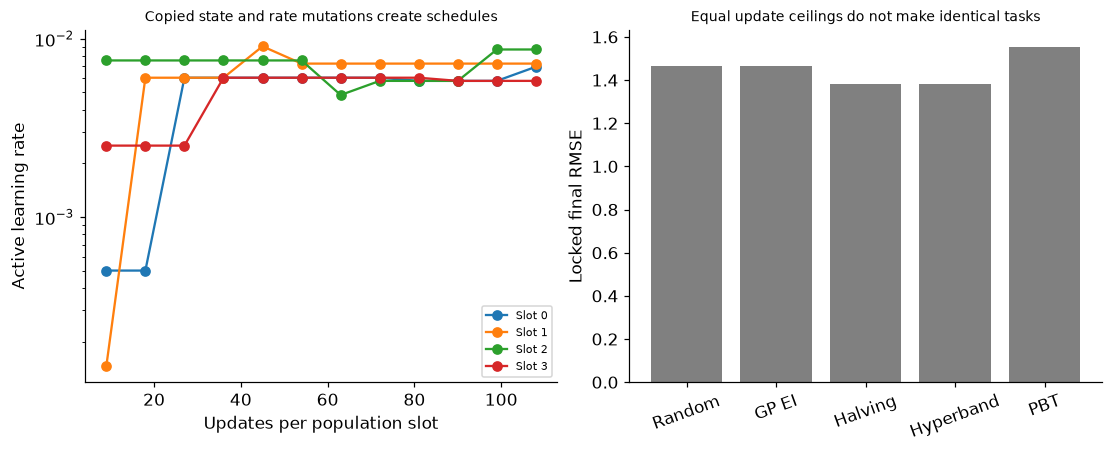

In [3]:
gr=np.random.default_rng(SEED+100);population=[];settings=[]
for idx in gr.choice(64,4,replace=False):
    c=copy.deepcopy(configs[idx]);m,o=fresh(c);population.append((m,o));settings.append(c)
history=[];transfers=[]
for block in range(12):
    for m,o in population:advance(m,o,9)
    losses=[dev_loss(m) for m,o in population];history.append({'updates_per_slot':(block+1)*9,'losses':losses,'learning_rates':[c['learning_rate'] for c in settings]})
    if block<11:
        best=int(np.argmin(losses));worst=int(np.argmax(losses));donor,donor_opt=population[best];recipient,recipient_opt=population[worst];recipient.load_state_dict(copy.deepcopy(donor.state_dict()));recipient_opt.load_state_dict(copy.deepcopy(donor_opt.state_dict()));assert all(torch.equal(a,b) for a,b in zip(donor.parameters(),recipient.parameters()));c=copy.deepcopy(settings[best]);c['learning_rate']=float(np.clip(c['learning_rate']*gr.choice([.8,1.2]),1e-4,.1));c['weight_decay']=float(np.clip(c['weight_decay']*gr.choice([.8,1.2]),1e-6,.1));settings[worst]=c
        for param_group in recipient_opt.param_groups:param_group.update(lr=c['learning_rate'],weight_decay=c['weight_decay'])
        transfers.append({'at_updates':(block+1)*9,'donor':best,'recipient':worst,'new_learning_rate':c['learning_rate'],'new_weight_decay':c['weight_decay']})
pbt_slot=int(np.argmin(history[-1]['losses']));assessments=[]
for name,(_,idx,m) in winners.items():
    with torch.no_grad():pred=m(fx).squeeze(1).numpy()
    assessments.append({'method':name,'selected_candidate':idx,'final_RMSE':float(np.sqrt(np.mean((pred-Y[final])**2))),'search_update_cost':costs[name]})
with torch.no_grad():pred=population[pbt_slot][0](fx).squeeze(1).numpy()
assessments.append({'method':'PBT schedule','selected_candidate':pbt_slot,'final_RMSE':float(np.sqrt(np.mean((pred-Y[final])**2))),'search_update_cost':432});assert len(transfers)==11 and len(history)==12 and len(assessments)==5;assert all(np.isfinite(r['final_RMSE']) for r in assessments)
RESULTS.update(PBT_history=history,PBT_state_transfers=transfers,PBT_updates=432,PBT_selected_slot=pbt_slot,final_assessments=assessments,final_used_for_search=False,static_horizon_equals_PBT_horizon=False)
display(pd.DataFrame(assessments));fig,axes=plt.subplots(1,2,figsize=(10,4))
for slot in range(4):axes[0].plot([r['updates_per_slot'] for r in history],[r['learning_rates'][slot] for r in history],marker='o',label=f'Slot {slot}')
axes[0].set(xlabel='Updates per population slot',ylabel='Active learning rate',yscale='log',title='Copied state and rate mutations create schedules');axes[0].legend(fontsize=7);axes[1].bar(range(5),[r['final_RMSE'] for r in assessments],color='.5');axes[1].set(xticks=range(5),xticklabels=['Random','GP EI','Halving','Hyperband','PBT'],ylabel='Locked final RMSE',title='Equal update ceilings do not make identical tasks');axes[1].tick_params(axis='x',rotation=20);plt.show()


In [4]:
summary={'example_id':'code_184','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual random and Gaussian-process expected-improvement search', 'actual successive halving and Hyperband bracket allocation', 'explicit restart cost with a common 432-update ceiling', 'actual synchronous population weight and optimizer transfer with rate mutation', 'locked final assessment and actual elimination visual'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual random and Gaussian-process expected-improvement search", "actual successive halving and Hyperband bracket allocation", "explicit restart cost with a common 432-update ceiling", "actual synchronous population weight and optimizer transfer with rate mutation", "locked final assessment and actual elimination visual"], "elapsed_seconds": 1.12, "example_id": "code_184", "hardware": "Darwin arm64 CPU", "results": {"GP_acquisition_candidate_ids": [54, 24, 9, 39, 16, 15, 53, 56, 34, 1, 37, 45, 44, 60, 59, 62], "GP_kernel_parameters_fixed": true, "PBT_history": [{"learning_rates": [0.0005009966984900764, 0.00014578241768560193, 0.0075576460462713135, 0.0025158955176194714], "losses": [1.5276416067916028, 1.544607748284166, 1.1914610443451439, 1.4346048822726611], "updates_per_slot": 9}, {"learning_rates": [0.0005009966984900764, 0.006046116837017051, 0.0075576460462713135, 0.0025158955176194714], "losses": [1.5034829692998997, 0.9518303